In [1]:
import pandas as pd
import numpy as np

In [4]:
main = "/Users/linhtrankhanh/Downloads/imc competition/data/round1"

price_0 = pd.read_csv(f"{main}/prices_round_1_day_0.csv", sep=';')
price_m1 = pd.read_csv(f"{main}/prices_round_1_day_-1.csv", sep=';')
price_m2 = pd.read_csv(f"{main}/prices_round_1_day_-2.csv", sep=';')


trade_0 = pd.read_csv(f"{main}/trades_round_1_day_0.csv", sep=';')
trade_m1 = pd.read_csv(f"{main}/trades_round_1_day_-1.csv", sep=';')
trade_m2 = pd.read_csv(f"{main}/trades_round_1_day_-2.csv", sep=';')
print(price_0['timestamp'].describe())
print(price_m1['timestamp'].describe())
print(price_m2['timestamp'].describe())

count     20000.0000
mean     499950.0000
std      288682.3503
min           0.0000
25%      249975.0000
50%      499950.0000
75%      749925.0000
max      999900.0000
Name: timestamp, dtype: float64
count     20000.0000
mean     499950.0000
std      288682.3503
min           0.0000
25%      249975.0000
50%      499950.0000
75%      749925.0000
max      999900.0000
Name: timestamp, dtype: float64
count     20000.0000
mean     499950.0000
std      288682.3503
min           0.0000
25%      249975.0000
50%      499950.0000
75%      749925.0000
max      999900.0000
Name: timestamp, dtype: float64


In [5]:
trade_tables = [trade_0, trade_m1, trade_m2]
trade_0['day'] = 0
trade_m1['day'] = -1
trade_m2['day'] = -2

combined_trade = pd.concat(trade_tables)
combined_trade = combined_trade[['day','timestamp','symbol','currency', 'price','quantity']] #drop seller and buyer columns since it's all NaN

ANCHOR = pd.Timestamp("2026-01-01")  # arbitrary “day 0” start

def add_prosperity_datetime(df: pd.DataFrame):
    out = df.copy()
    # Each timestamp unit = 100ms = 0.1 seconds
    out["dt"] = (ANCHOR 
                 + pd.to_timedelta(out["day"], unit="D") 
                 + pd.to_timedelta(out["timestamp"] * 100, unit="ms"))
    return out

# example
trades = add_prosperity_datetime(combined_trade).sort_values("dt")
trades = trades[['dt','day','timestamp','symbol','currency', 'price','quantity']]
print(trades.head(10))
print(trades.tail(10))
print(trades.describe())
print(trades.dtypes)

                   dt  day  timestamp                symbol currency    price  \
0 2025-12-30 00:01:10   -2        700     ASH_COATED_OSMIUM   XIRECS   9990.0   
1 2025-12-30 00:01:30   -2        900     ASH_COATED_OSMIUM   XIRECS   9998.0   
2 2025-12-30 00:01:40   -2       1000  INTARIAN_PEPPER_ROOT   XIRECS   9995.0   
3 2025-12-30 00:04:10   -2       2500     ASH_COATED_OSMIUM   XIRECS  10011.0   
4 2025-12-30 00:06:40   -2       4000  INTARIAN_PEPPER_ROOT   XIRECS  10007.0   
5 2025-12-30 00:10:10   -2       6100     ASH_COATED_OSMIUM   XIRECS  10013.0   
6 2025-12-30 00:17:30   -2      10500  INTARIAN_PEPPER_ROOT   XIRECS  10013.0   
7 2025-12-30 00:21:00   -2      12600  INTARIAN_PEPPER_ROOT   XIRECS  10018.0   
8 2025-12-30 00:21:30   -2      12900     ASH_COATED_OSMIUM   XIRECS  10001.0   
9 2025-12-30 00:23:00   -2      13800     ASH_COATED_OSMIUM   XIRECS  10017.0   

   quantity  
0         6  
1         2  
2         7  
3         8  
4         7  
5         8  
6         

In [6]:
price_tables = [price_0, price_m1, price_m2]

for table in price_tables:
    print('Day',table['day'].unique())
    print('ASH_COATED_OSMIUM',table[table['product'] == 'ASH_COATED_OSMIUM']['mid_price'].describe())
    print('--------------')
    print('INTARIAN_PEPPER_ROOT',table[table['product'] == 'INTARIAN_PEPPER_ROOT']['mid_price'].describe())
    print('--------------')

combined_price = pd.concat(price_tables)
prices = add_prosperity_datetime(combined_price).sort_values("dt")
prices = prices[['dt','day', 'timestamp','product', 'bid_price_1', 'bid_volume_1', 'bid_price_2', 'bid_volume_2', 'bid_price_3', 'bid_volume_3', 'ask_price_1', 'ask_volume_1', 'ask_price_2', 'ask_volume_2', 'ask_price_3', 'ask_volume_3', 'mid_price', 'profit_and_loss']]
# print(prices.head(5))
# print(prices.describe())

Day [0]
ASH_COATED_OSMIUM count    10000.000000
mean      9987.605950
std        374.025689
min          0.000000
25%       9998.000000
50%      10002.000000
75%      10005.000000
max      10023.000000
Name: mid_price, dtype: float64
--------------
INTARIAN_PEPPER_ROOT count    10000.000000
mean     12473.922650
std        640.834024
min          0.000000
25%      12248.500000
50%      12499.000000
75%      12750.000000
max      13007.000000
Name: mid_price, dtype: float64
--------------
Day [-1]
ASH_COATED_OSMIUM count    10000.000000
mean      9983.832550
std        412.038897
min          0.000000
25%       9998.000000
50%      10001.000000
75%      10003.000000
max      10019.000000
Name: mid_price, dtype: float64
--------------
INTARIAN_PEPPER_ROOT count    10000.000000
mean     11480.480000
std        554.666152
min          0.000000
25%      11249.375000
50%      11499.500000
75%      11749.500000
max      12006.000000
Name: mid_price, dtype: float64
--------------
Day [-2]
ASH_

In [8]:
# # Check how many rows were affected
# bad = prices[prices["mid_price"].isna() | (prices["mid_price"] == 0)]
# bad
# # print(bad.groupby(["day", "product"]).size())


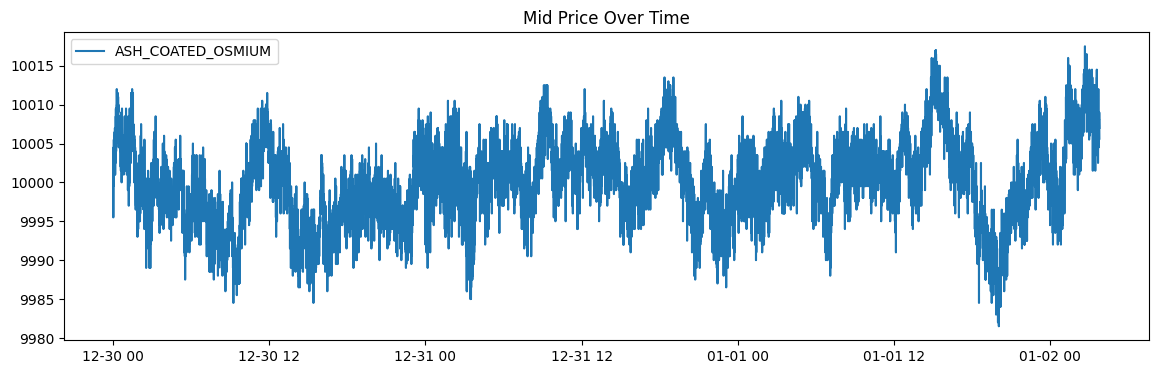

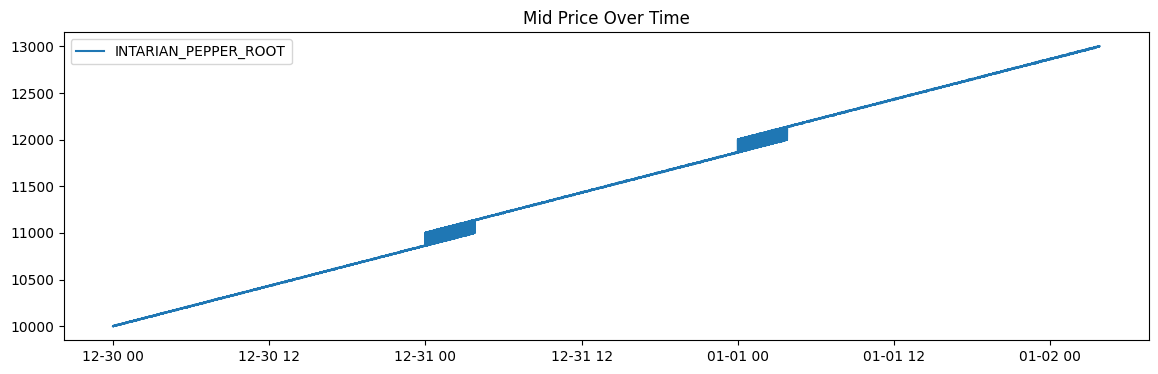

ASH_COATED_OSMIUM: ADF p-value = 0.0000
INTARIAN_PEPPER_ROOT: ADF p-value = 0.9449


In [9]:
# Use NaN mid for ALL signal calculations
prices["mid_clean"] = np.where(
    prices["bid_price_1"].notna() & prices["ask_price_1"].notna(),
    (prices["bid_price_1"] + prices["ask_price_1"]) / 2,
    np.nan
)

# Only forward-fill for plotting/display
prices["mid_plot"] = prices.groupby("product")["mid_clean"].ffill()

# NEVER use mid_plot for ADF, OBI, or correlation — it artificially
# reduces variance and inflates stationarity/correlation results

import matplotlib.pyplot as plt

for product, grp in prices.groupby("product"):
    plt.figure(figsize=(14, 4))
    plt.plot(grp["dt"], grp["mid_plot"], label=product)
    plt.legend(); 
    plt.title("Mid Price Over Time"); 
    plt.show()

# Check for mean reversion (stationary) vs trending
from statsmodels.tsa.stattools import adfuller

for product, grp in prices.groupby("product"):
    result = adfuller(grp["mid_clean"].dropna())
    print(f"{product}: ADF p-value = {result[1]:.4f}")
    # p < 0.05 → mean-reverting → good for market making
    # p > 0.05 → trending → lean toward momentum


In [ ]:
list_day = prices['day'].unique()
for day, day_grp in prices.groupby("day"):
    print(f"Day {day}")
    for product, grp in day_grp.groupby("product"):
        print(f"{product}")
        print(grp["mid_clean"].describe())
        print("--------------")
        
print('Cosolidated prices')
print('ASH_COATED_OSMIUM',prices[prices['product'] == 'ASH_COATED_OSMIUM']['mid_clean'].describe())
print('--------------')
print('INTARIAN_PEPPER_ROOT',prices[prices['product'] == 'INTARIAN_PEPPER_ROOT']['mid_clean'].describe())
print('--------------')



Day -2
ASH_COATED_OSMIUM
count     9187.000000
mean      9998.161750
std          4.726266
min       9984.500000
25%       9995.000000
50%       9998.000000
75%      10002.000000
max      10012.000000
Name: mid_clean, dtype: float64
--------------
INTARIAN_PEPPER_ROOT
count     9216.000000
mean     10500.567057
std        287.932430
min       9998.500000
25%      10251.000000
50%      10501.750000
75%      10750.000000
max      11001.500000
Name: mid_clean, dtype: float64
--------------
Day -1
ASH_COATED_OSMIUM
count     9225.000000
mean     10000.833550
std          3.825387
min       9986.500000
25%       9998.000000
50%      10001.000000
75%      10003.000000
max      10013.500000
Name: mid_clean, dtype: float64
--------------
INTARIAN_PEPPER_ROOT
count     9219.000000
mean     11501.409155
std        287.640269
min      10998.000000
25%      11253.000000
50%      11502.500000
75%      11750.500000
max      12001.000000
Name: mid_clean, dtype: float64
--------------
Day 0
ASH_COATED

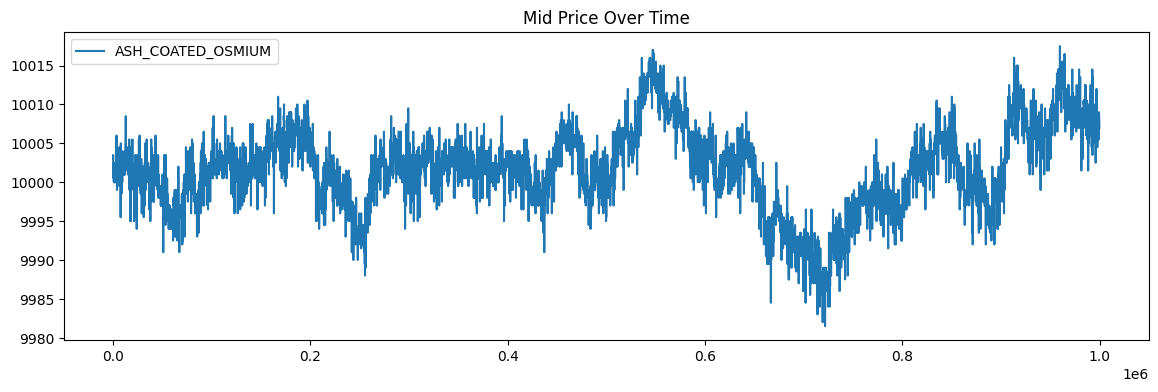

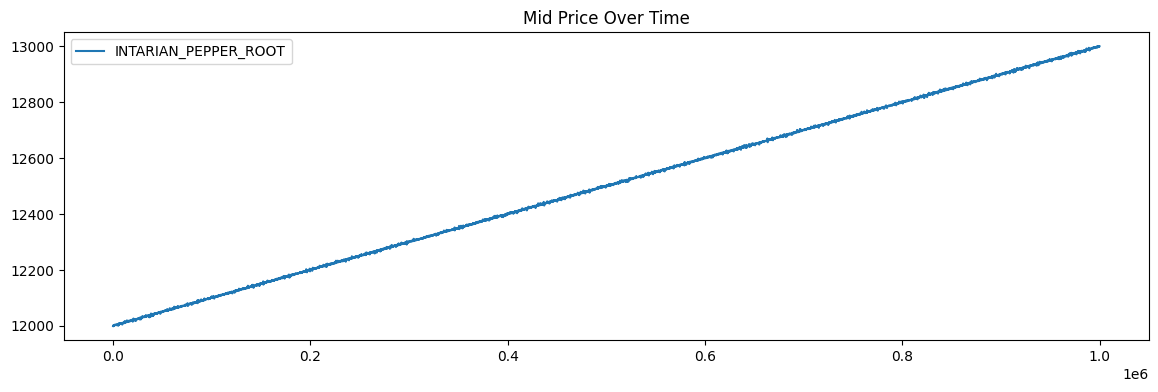

In [31]:
# aco_prices = prices[prices['product'] == 'ASH_COATED_OSMIUM']
# aco_trades = trades[trades['symbol'] == 'ASH_COATED_OSMIUM']
# # print('Prices of ASH_COATED_OSMIUM:', aco_prices.describe())
# # print('--------------------------------')
# # print('Trades of ASH_COATED_OSMIUM:', aco_trades.describe())
# # print('--------------------------------')
# # print('No.nan values of ASH_COATED_OSMIUM:', aco_prices.isna().sum())
# # print('--------------------------------')
# # print('Data types of ASH_COATED_OSMIUM:', aco_prices.dtypes)

# aco_prices["mid_clean"] = np.where(
#     aco_prices["bid_price_1"].notna() & aco_prices["ask_price_1"].notna(),
#     (aco_prices["bid_price_1"] + aco_prices["ask_price_1"]) / 2,
#     np.nan
# )
# # aco_prices.head()

# returns = aco_prices["mid_clean"].diff()

# autocorr = returns.autocorr(lag=1)
# print("Lag-1 autocorrelation:", autocorr)

# deviation = aco_prices["mid_clean"] - 10000
# print(deviation.describe())

# # bucket deviations
# aco_prices["dev_bucket"] = np.round(deviation)

# # next price move
# aco_prices["future_return"] = aco_prices["mid_clean"].shift(-1) - aco_prices["mid_clean"]

# signal = aco_prices.groupby("dev_bucket")["future_return"].mean()
# print(signal)

# aco_prices["spread"] = aco_prices["ask_price_1"] - aco_prices["bid_price_1"]
# print(aco_prices["spread"].describe())

# aco_prices["imbalance"] = (
#     aco_prices["bid_volume_1"] - aco_prices["ask_volume_1"]
# ) / (aco_prices["bid_volume_1"] + aco_prices["ask_volume_1"])

# # signal = aco_prices.groupby(pd.qcut(aco_prices["imbalance"], 10))["future_return"].mean()
# # print(signal)

# deviation = aco_prices["mid_clean"] - 10000

# aco_prices["abs_dev"] = np.abs(deviation)

# # how fast it shrinks
# aco_prices["dev_change"] = aco_prices["abs_dev"].diff()

# print(aco_prices["dev_change"].mean())

# for offset in range(1, 10):
#     hit_rate = np.mean(
#         (aco_prices["mid_clean"] - 10000).abs() >= offset
#     )
#     print(f"Offset {offset}: {hit_rate}")


# aco_prices["edge"] = aco_prices["ask_price_1"] - 10000
# print(aco_prices[aco_prices["edge"] < -5].head())
# Use NaN mid for ALL signal calculations
price_0["mid_clean"] = np.where(
    price_0["bid_price_1"].notna() & price_0["ask_price_1"].notna(),
    (price_0["bid_price_1"] + price_0["ask_price_1"]) / 2,
    np.nan
)

# Only forward-fill for plotting/display
price_0["mid_plot"] = price_0.groupby("product")["mid_clean"].ffill()
for product, grp in price_0.groupby("product"):
    plt.figure(figsize=(14, 4))
    plt.plot(grp["timestamp"], grp["mid_plot"], label=product)
    plt.legend(); 
    plt.title("Mid Price Over Time"); 
    plt.show()